# 09_12 Priors as Regularisers: Ridge, Lasso and MAP

**Learning objectives**
- Show that **ridge regression is the MAP estimate under a Gaussian prior** and **lasso is the MAP estimate under a Laplace prior**, with $\lambda=\sigma^2/\tau^2$ (ridge) and $\lambda=\sigma^2/b$ (lasso); read **weight decay** as the same thing.
- Derive the **closed-form shrinkage** of each prior in an orthonormal design (ridge: divide by $1+\lambda$; lasso: soft-threshold), and the **bias and variance** of the ridge estimator.
- Implement ridge, lasso (coordinate descent), elastic net and the **full Bayesian posterior** from scratch; choose $\lambda$ by **cross-validation** or by the **marginal likelihood**.
- Compare priors when the truth is **sparse** or **dense**, and see why **gradient descent with weight decay or early stopping** behaves like ridge.

**Prerequisites:** [07_01 Bayesian updating](../../module_07_bayesian/notebooks/07_01_bayesian_updating_conjugates.ipynb), [06_01 Maximum likelihood](../../module_06_inference/notebooks/06_01_mle_method_of_moments.ipynb), [09_01 Losses as likelihoods](09_01_losses_as_likelihoods.ipynb), [09_10 Gaussian processes](09_10_gaussian_processes.ipynb) (Bayesian linear regression).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
Bayes' rule: posterior $\propto$ likelihood $\times$ prior. For $y=Xw+\varepsilon$, $\varepsilon\sim N(0,\sigma^2I)$ the log-likelihood is $-\frac1{2\sigma^2}\|y-Xw\|^2+\text{const}$, so maximum likelihood is least squares (09_01). The **MAP** estimate maximises the posterior; with a Gaussian prior and Gaussian noise the posterior is Gaussian (07_01).

## 3. Intuition and story
With 60 customers and 30 candidate features, least squares will happily fit the noise: some coefficients will be huge and wrong, because many combinations explain the 60 numbers equally well. A **prior** says what coefficients are plausible *before* seeing the data: "most are small" (Gaussian) or "most are exactly zero and a few are large" (Laplace). Combined with the likelihood, the prior pulls the estimate towards zero. This pull is **regularisation**, and the two famous penalties are nothing but the negative log of two famous priors: $\lambda\|w\|^2$ is a Gaussian prior, $\lambda\|w\|_1$ a Laplace prior. Seeing regularisation as a prior explains how to set its strength ($\lambda=$ noise variance over prior variance), what it does to the uncertainty (the full posterior), and when each form is the right belief.

## 4. Formal definitions

Model $y=Xw+\varepsilon$, $\varepsilon\sim N(0,\sigma^2I)$, with $n$ observations and $p$ features.

| Estimator | Prior on each $w_j$ | Objective (to minimise) | Solution |
|---|---|---|---|
| **OLS** (MLE) | flat | $\frac12\|y-Xw\|^2$ | $(X^\top X)^{-1}X^\top y$ |
| **Ridge** (MAP, Gaussian) | $N(0,\tau^2)$ | $\frac12\|y-Xw\|^2+\frac\lambda2\|w\|_2^2$, $\ \lambda=\sigma^2/\tau^2$ | $(X^\top X+\lambda I)^{-1}X^\top y$ |
| **Lasso** (MAP, Laplace) | $\mathrm{Laplace}(0,b)$ | $\frac12\|y-Xw\|^2+\lambda\|w\|_1$, $\ \lambda=\sigma^2/b$ | coordinate descent / soft-thresholding |
| **Elastic net** | Gaussian-Laplace mixture | $\frac12\|y-Xw\|^2+\lambda_1\|w\|_1+\frac{\lambda_2}2\|w\|^2$ | coordinate descent |
| **Full Bayes (ridge)** | $N(0,\tau^2)$ | posterior $N(\hat w,\ \sigma^2(X^\top X+\lambda I)^{-1})$ | closed form |

**Orthonormal design** ($X^\top X=I$, OLS estimate $z_j$): ridge $\hat w_j=z_j/(1+\lambda)$; lasso $\hat w_j=\mathrm{sign}(z_j)\max(|z_j|-\lambda,0)$. **Log marginal likelihood (evidence)** of the ridge model: $\ y\sim N(0,\sigma^2I+\tau^2XX^\top)$.

## 5. Derivations

### 5.1 Ridge is MAP under a Gaussian prior
$-\ln p(w|y)=\frac1{2\sigma^2}\|y-Xw\|^2+\frac1{2\tau^2}\|w\|^2+\text{const}$. Multiplying by $\sigma^2$ gives $\frac12\|y-Xw\|^2+\frac\lambda2\|w\|^2$ with $\lambda=\sigma^2/\tau^2$. Setting the gradient to zero: $(X^\top X+\lambda I)w=X^\top y$. **In plain words.** A Gaussian prior says each coefficient is probably within $\pm\tau$ of zero; the stronger the belief (small $\tau$) or the noisier the data (large $\sigma$), the bigger the penalty $\lambda$.

### 5.2 Lasso is MAP under a Laplace prior
With $p(w_j)=\frac1{2b}e^{-|w_j|/b}$ the negative log-posterior is $\frac1{2\sigma^2}\|y-Xw\|^2+\frac1b\|w\|_1$, i.e. $\frac12\|y-Xw\|^2+\lambda\|w\|_1$ with $\lambda=\sigma^2/b$. The $\ell_1$ term is not differentiable at 0, and its subgradient allows $w_j=0$ whenever $|X_j^\top r_j|\le\lambda$ ($r_j$ the partial residual). **In plain words.** The Laplace prior has a sharp peak at zero and heavy tails: it believes most coefficients are exactly zero but a few can be large, so it zeroes out small ones and shrinks big ones by a constant amount.

### 5.3 Orthonormal design: shrinkage formulas
With $X^\top X=I$ the objective separates into coordinates: $\frac12(w_j-z_j)^2+\frac\lambda2w_j^2$ gives $w_j=z_j/(1+\lambda)$; $\frac12(w_j-z_j)^2+\lambda|w_j|$ gives the soft-threshold $\mathrm{sign}(z_j)(|z_j|-\lambda)_+$. **In plain words.** Ridge shrinks everything by the same *fraction*; lasso subtracts the same *amount* and sets small estimates to exactly zero.

### 5.4 Bias and variance of ridge
Orthonormal design, $z_j\sim N(w_j,\sigma^2)$: $E\hat w_j=\frac{w_j}{1+\lambda}$ (bias $-\frac{\lambda}{1+\lambda}w_j$) and $\mathrm{Var}\hat w_j=\frac{\sigma^2}{(1+\lambda)^2}$; the MSE $\frac{\lambda^2w_j^2+\sigma^2}{(1+\lambda)^2}$ is smaller than the OLS MSE $\sigma^2$ whenever $\lambda<\frac{2\sigma^2}{w_j^2-\sigma^2}$ (for $|w_j|>\sigma$), and always for small $\lambda$ if $|w_j|<\sigma\sqrt{1+2/\lambda}$. **In plain words.** Shrinkage buys a lower variance at the price of a bias; it wins when the true coefficients are not much larger than the noise.

### 5.5 The full posterior and the evidence
With the Gaussian prior the posterior is exactly $N(\hat w_{\mathrm{ridge}},\ \sigma^2(X^\top X+\lambda I)^{-1})$: the MAP is its mean, and credible intervals come with it. Integrating $w$ out gives $y\sim N(0,\sigma^2I+\tau^2XX^\top)$, whose log-density can be maximised over $\tau$ (and $\sigma$) to choose $\lambda=\sigma^2/\tau^2$ without cross-validation. **In plain words.** Ridge is not just a point estimate: it comes with uncertainty, and the data themselves tell how strong the prior should be.

### 5.6 Weight decay and early stopping
Gradient descent on $\frac12\|y-Xw\|^2+\frac\lambda2\|w\|^2$ with step $\eta$ is $w\leftarrow(1-\eta\lambda)w-\eta X^\top(Xw-y)$: the factor $(1-\eta\lambda)$ is **weight decay**. Gradient descent on the unregularised loss, stopped after $k$ steps, has in each eigen-direction of $X^\top X$ (eigenvalue $s$) the shrinkage factor $1-(1-\eta s)^k$, similar to ridge's $s/(s+\lambda)$ with $\lambda\approx1/(\eta k)$. **In plain words.** Training a network with weight decay or stopping early both keep the weights small, which is, statistically, a Gaussian prior.

## 6. Properties and relationships
- **Shrinkage towards the prior mean** is the common effect; the shape of the prior decides the pattern: ridge shrinks all coefficients smoothly and keeps correlated ones together, lasso selects a sparse subset and arbitrarily picks one of a group of correlated features, elastic net does both.
- **MAP is not the posterior mean** for the Laplace prior (lasso's solution is a mode, and sparse; the Bayesian lasso posterior mean is not sparse).
- **Choosing $\lambda$:** cross-validation, the evidence (marginal likelihood), or information criteria; a good $\lambda$ depends on the signal-to-noise ratio and on $n/p$.
- **Standardise the features** before penalising; otherwise the penalty depends on the units.
- **Generalised to any model:** regularised logistic regression, neural nets (weight decay = Gaussian prior; $\ell_1$ = Laplace), and Bayesian neural networks that keep the whole posterior.
- **Link to ML and AI:** weight decay (AdamW) in every deep-learning recipe, sparse models and feature selection, compressed sensing, priors on LLM adapter weights (LoRA with weight decay), early stopping, dropout as approximate Bayesian regularisation (09_06), and the MAP view of fine-tuning with a KL penalty to a reference model.

## 7. Ridge, lasso and the Bayesian posterior from scratch

Ridge in closed form, lasso and elastic net by coordinate descent (soft-thresholding), the Gaussian posterior, the evidence and a K-fold cross-validation helper.

In [2]:
def soft(x, t): return np.sign(x) * np.maximum(np.abs(x) - t, 0.0)
def ridge(X, y, lam): return np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ y)
def enet(X, y, l1, l2=0.0, iters=2000, tol=1e-10, w0=None):
    n, p = X.shape; w = np.zeros(p) if w0 is None else w0.copy(); r = y - X @ w; col = (X ** 2).sum(axis=0)
    for it in range(iters):
        wmax = 0.0
        for j in range(p):
            rho = X[:, j] @ r + col[j] * w[j]; wn = soft(rho, l1) / (col[j] + l2); d = wn - w[j]
            if d != 0.0: r -= X[:, j] * d; w[j] = wn; wmax = max(wmax, abs(d))
        if wmax < tol: break
    return w
def posterior(X, y, sigma, tau): A = X.T @ X / sigma ** 2 + np.eye(X.shape[1]) / tau ** 2; S = np.linalg.inv(A); return S @ X.T @ y / sigma ** 2, S
def log_evidence(X, y, sigma, tau): C = sigma ** 2 * np.eye(len(y)) + tau ** 2 * X @ X.T; return stats.multivariate_normal(np.zeros(len(y)), C).logpdf(y)
def cv_err(fit, X, y, K=5, seed=0):
    idx = np.random.default_rng(seed).permutation(len(y)); folds = np.array_split(idx, K); e = 0.0
    for f in folds: tr = np.setdiff1d(idx, f); e += np.sum((y[f] - X[f] @ fit(X[tr], y[tr])) ** 2)
    return e / len(y)
g = np.random.default_rng(0); n, p = 50, 8; X = g.normal(size=(n, p)); w_true = np.array([2.0, -1.5, 0, 0, 1.0, 0, 0, 0]); y = X @ w_true + 0.5 * g.normal(size=n); sigma, tau = 0.5, 1.0; lam = sigma ** 2 / tau ** 2
mu_p, S_p = posterior(X, y, sigma, tau); print("ridge = posterior mean (max abs difference):", np.abs(ridge(X, y, lam) - mu_p).max())
w_l = enet(X, y, 5.0); sub = np.where(np.abs(w_l) > 0)[0]; kkt = X.T @ (y - X @ w_l); print("lasso solution:", w_l.round(3), "| KKT: |X^T r| <= lambda on the zeros:", np.abs(kkt[w_l == 0]).max().round(3), "<= 5 and = lambda * sign on the non-zeros:", np.round(kkt[w_l != 0], 3))
assert np.abs(ridge(X, y, lam) - mu_p).max() < 1e-10 and np.abs(kkt[w_l == 0]).max() <= 5 + 1e-6 and np.allclose(np.abs(kkt[w_l != 0]), 5.0, atol=1e-5)

ridge = posterior mean (max abs difference): 4.440892098500626e-16
lasso solution: [ 1.843 -1.323  0.     0.     0.913  0.     0.     0.   ] | KKT: |X^T r| <= lambda on the zeros: 3.342 <= 5 and = lambda * sign on the non-zeros: [ 5. -5.  5.]


## 8. 2D visuals

### 8.1 Priors and penalties
Left: the Gaussian and the Laplace prior densities (same variance 1). Middle: the corresponding penalties $-\ln p$: a parabola and a V shape. Right: in two dimensions the **constraint regions** equivalent to the penalties (a disc for ridge, a diamond for lasso) with elliptical loss contours: the lasso solution sits at a corner of the diamond, where one coefficient is exactly zero.

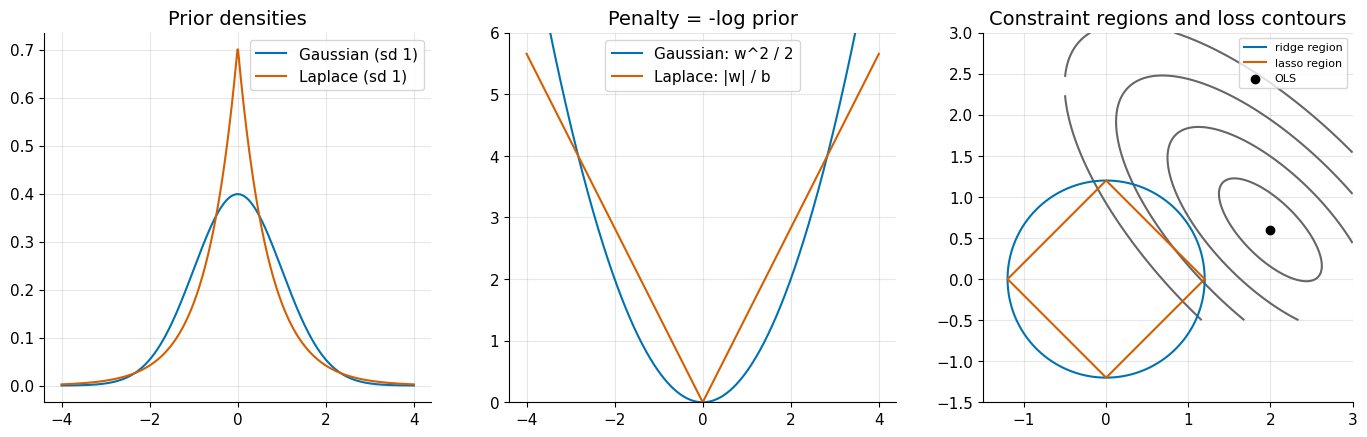

variance of both priors: 1.0 1.0 | density at 0: Gaussian 0.399 Laplace 0.707


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); xg = np.linspace(-4, 4, 600); b = 1 / np.sqrt(2); axes[0].plot(xg, stats.norm.pdf(xg), color=MAIN, label="Gaussian (sd 1)"); axes[0].plot(xg, stats.laplace.pdf(xg, scale=b), color=HIGHLIGHT, label="Laplace (sd 1)"); axes[0].legend(); axes[0].set_title("Prior densities")
axes[1].plot(xg, 0.5 * xg ** 2, color=MAIN, label="Gaussian: w^2 / 2"); axes[1].plot(xg, np.abs(xg) / b, color=HIGHLIGHT, label="Laplace: |w| / b"); axes[1].set_ylim(0, 6); axes[1].legend(); axes[1].set_title("Penalty = -log prior")
w1, w2 = np.meshgrid(np.linspace(-0.5, 3, 300), np.linspace(-0.5, 3, 300)); wo = np.array([2.0, 0.6]); Hh = np.array([[1.0, 0.7], [0.7, 1.0]]); L = 0.5 * ((w1 - wo[0]) ** 2 * Hh[0, 0] + 2 * (w1 - wo[0]) * (w2 - wo[1]) * Hh[0, 1] + (w2 - wo[1]) ** 2 * Hh[1, 1])
axes[2].contour(w1, w2, L, levels=[0.1, 0.4, 0.9, 1.6], colors=NEUTRAL); t = np.linspace(0, 2 * np.pi, 300); axes[2].plot(1.2 * np.cos(t), 1.2 * np.sin(t), color=MAIN, label="ridge region"); axes[2].fill([1.2, 0, -1.2, 0, 1.2], [0, 1.2, 0, -1.2, 0], alpha=0.0); axes[2].plot([1.2, 0, -1.2, 0, 1.2], [0, 1.2, 0, -1.2, 0], color=HIGHLIGHT, label="lasso region"); axes[2].scatter(*wo, color="black", zorder=3, label="OLS"); axes[2].set_xlim(-1.5, 3); axes[2].set_ylim(-1.5, 3); axes[2].set_aspect("equal"); axes[2].legend(fontsize=8); axes[2].set_title("Constraint regions and loss contours")
plt.show(); print("variance of both priors:", 1.0, round(float(stats.laplace.var(scale=b)), 4), "| density at 0: Gaussian", round(float(stats.norm.pdf(0)), 3), "Laplace", round(float(stats.laplace.pdf(0, scale=b)), 3)); assert abs(stats.laplace.var(scale=b) - 1) < 1e-12

### 8.2 Coefficient paths
The 30 coefficients of a regression with 60 observations and 5 truly non-zero coefficients (colours) as the penalty grows: ridge shrinks all of them smoothly towards zero but never to zero; the lasso path is piecewise linear and drops the noise coefficients first.

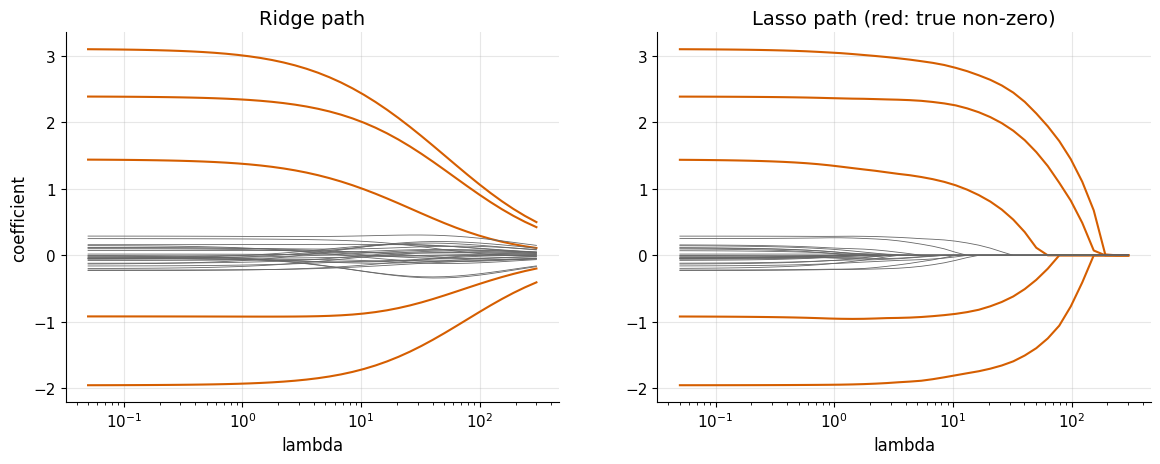

number of non-zero lasso coefficients at lambda = 0.05, 5, 20, 100, 300: [30, 12, 6, 3, 0] | non-zero ridge coefficients (always): 30


In [4]:
g = np.random.default_rng(1); n, p = 60, 30; Xp = g.normal(size=(n, p)); wt = np.zeros(p); wt[:5] = [3.0, -2.0, 1.5, -1.0, 2.5]; yp = Xp @ wt + 1.0 * g.normal(size=n); lams = np.geomspace(0.05, 300, 40); pr = np.array([ridge(Xp, yp, l) for l in lams]); pl = []; w_ = np.zeros(p)
for l in lams[::-1]: w_ = enet(Xp, yp, l, w0=w_); pl.append(w_.copy())
pl = np.array(pl)[::-1]; fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for j in range(p): axes[0].semilogx(lams, pr[:, j], color=HIGHLIGHT if j < 5 else NEUTRAL, linewidth=1.5 if j < 5 else 0.6); axes[1].semilogx(lams, pl[:, j], color=HIGHLIGHT if j < 5 else NEUTRAL, linewidth=1.5 if j < 5 else 0.6)
axes[0].set_xlabel("lambda"); axes[0].set_ylabel("coefficient"); axes[0].set_title("Ridge path"); axes[1].set_xlabel("lambda"); axes[1].set_title("Lasso path (red: true non-zero)")
plt.show(); nz = (np.abs(pl) > 1e-8).sum(axis=1); print("number of non-zero lasso coefficients at lambda = 0.05, 5, 20, 100, 300:", [int(nz[np.argmin(np.abs(lams - l))]) for l in (0.05, 5, 20, 100, 300)], "| non-zero ridge coefficients (always):", int((np.abs(pr[-1]) > 1e-8).sum())); assert nz[0] > nz[-1] and nz[-1] == 0 and (np.abs(pr[-1]) > 1e-8).all()

### 8.3 Choosing $\lambda$: cross-validation and the evidence
Five-fold cross-validated error of ridge and lasso over $\lambda$ (left) and the log evidence of the Gaussian-prior model over $\lambda=\sigma^2/\tau^2$ (right): the evidence peak is near the cross-validation minimum.

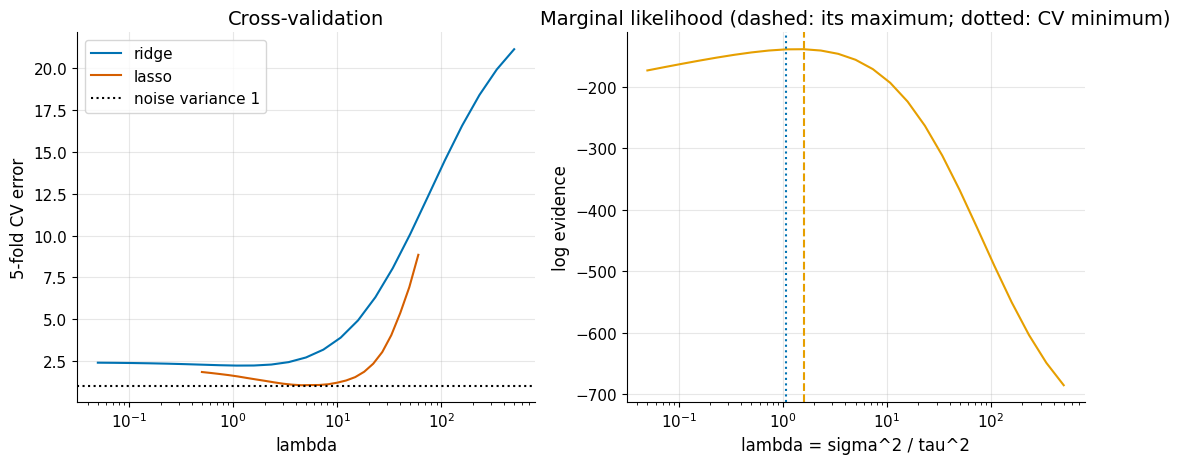

ridge: CV-best lambda 1.08 (error 2.234), evidence-best lambda 1.58 | lasso: CV-best lambda 4.49 (error 1.060) | OLS CV error 2.426


In [5]:
lam_r = np.geomspace(0.05, 500, 25); cvr = np.array([cv_err(lambda A, b_, l=l: ridge(A, b_, l), Xp, yp) for l in lam_r]); lam_l = np.geomspace(0.5, 60, 25); cvl = np.array([cv_err(lambda A, b_, l=l: enet(A, b_, l), Xp, yp) for l in lam_l])
s_hat = 1.0; ev = np.array([log_evidence(Xp, yp, s_hat, s_hat / np.sqrt(l)) for l in lam_r]); fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].semilogx(lam_r, cvr, color=MAIN, label="ridge"); axes[0].semilogx(lam_l, cvl, color=HIGHLIGHT, label="lasso"); axes[0].axhline(1.0, color="black", linestyle=":", label="noise variance 1"); axes[0].legend(); axes[0].set_xlabel("lambda"); axes[0].set_ylabel("5-fold CV error"); axes[0].set_title("Cross-validation")
axes[1].semilogx(lam_r, ev, color=SIM); axes[1].axvline(lam_r[np.argmax(ev)], color=SIM, linestyle="--"); axes[1].axvline(lam_r[np.argmin(cvr)], color=MAIN, linestyle=":"); axes[1].set_xlabel("lambda = sigma^2 / tau^2"); axes[1].set_ylabel("log evidence"); axes[1].set_title("Marginal likelihood (dashed: its maximum; dotted: CV minimum)")
plt.show(); print(f"ridge: CV-best lambda {lam_r[np.argmin(cvr)]:.2f} (error {cvr.min():.3f}), evidence-best lambda {lam_r[np.argmax(ev)]:.2f} | lasso: CV-best lambda {lam_l[np.argmin(cvl)]:.2f} (error {cvl.min():.3f}) | OLS CV error {cv_err(lambda A, b_: np.linalg.lstsq(A, b_, rcond=None)[0], Xp, yp):.3f}"); assert cvr.min() < cv_err(lambda A, b_: np.linalg.lstsq(A, b_, rcond=None)[0], Xp, yp) and cvl.min() < cvr.min() + 0.5

## 9. 3D visuals

### 9.1 Static: the MAP objective for two coefficients
The sum of the loss and the penalty for two coefficients: with the Gaussian prior (left) a smooth bowl whose minimum is pulled towards the origin; with the Laplace prior (right) a bowl with a crease along the axes, which can trap the minimum *on* an axis.

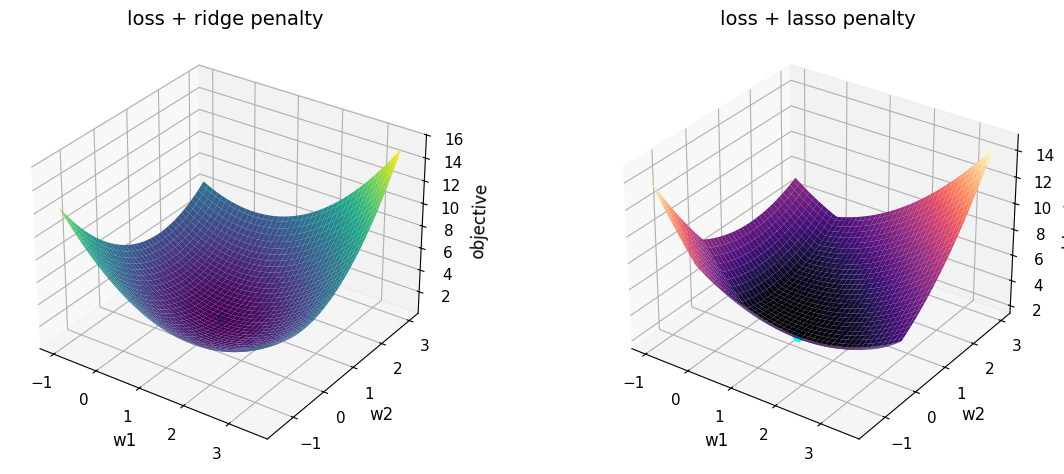

ridge minimum at (1.08, 0.69); lasso minimum at (1.19, 0.01) (second coefficient exactly zero when |w2| < grid step: True); OLS (2.0, 0.6) shifted by the correlation


In [6]:
w1, w2 = np.meshgrid(np.linspace(-1, 3.5, 120), np.linspace(-1.5, 3, 120)); L = 0.5 * ((w1 - 2.0) ** 2 + 2 * 0.7 * (w1 - 2.0) * (w2 - 0.6) + (w2 - 0.6) ** 2); lam = 0.8; Zr = L + 0.5 * lam * (w1 ** 2 + w2 ** 2); Zl = L + 1.2 * (np.abs(w1) + np.abs(w2)); fig = plt.figure(figsize=(14, 5.6))
for k, (Z, ttl) in enumerate([(Zr, "loss + ridge penalty"), (Zl, "loss + lasso penalty")]): ax = fig.add_subplot(1, 2, k + 1, projection="3d"); ax.plot_surface(w1, w2, Z, cmap=["viridis", "magma"][k], edgecolor="none"); i_ = np.unravel_index(Z.argmin(), Z.shape); ax.scatter([w1[i_]], [w2[i_]], [Z.min()], color="cyan", s=50); ax.set_xlabel("w1"); ax.set_ylabel("w2"); ax.set_zlabel("objective"); ax.set_title(ttl); ax.view_init(elev=30, azim=-55)
plt.show(); ir = np.unravel_index(Zr.argmin(), Zr.shape); il = np.unravel_index(Zl.argmin(), Zl.shape); print(f"ridge minimum at ({w1[ir]:.2f}, {w2[ir]:.2f}); lasso minimum at ({w1[il]:.2f}, {w2[il]:.2f}) (second coefficient exactly zero when |w2| < grid step: {abs(w2[il]) < 0.04}); OLS (2.0, 0.6) shifted by the correlation"); assert abs(w2[il]) < 0.05 and abs(w2[ir]) > 0.05

### 9.2 Interactive Plotly version of 9.1 (lasso panel)

In [7]:
fig = go.Figure(go.Surface(x=w1[0], y=w2[:, 0], z=Zl, colorscale="Magma")); fig.update_layout(title="Loss + lasso penalty", width=760, height=560, scene=dict(xaxis_title="w1", yaxis_title="w2", zaxis_title="objective")); fig.show()

### 9.3 Static: test error over (prior strength, sample size)
Ridge test MSE of a 20-feature regression ($\sigma=1$, coefficients $N(0,1)$) as a function of $\lambda$ and the number of observations $n$: when the prior is right the best $\lambda$ stays at $\sigma^2/\tau^2=1$ for every $n$, but what you gain over no regularisation shrinks quickly as $n$ grows (the likelihood dominates the prior); with few data the prior matters a lot.

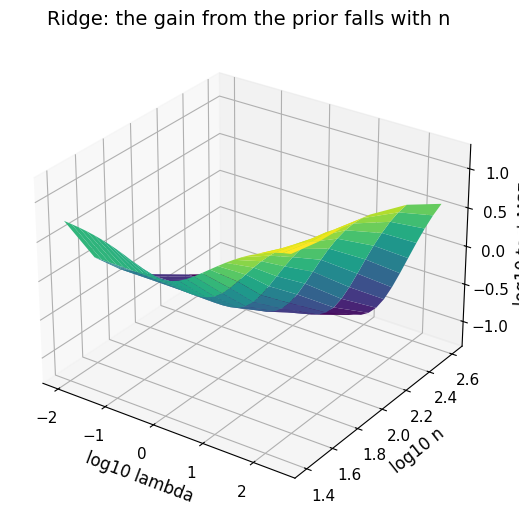

best lambda by n: {25: 1.02, 40: 1.02, 60: 1.02, 100: 0.71, 200: 1.02, 400: 1.02} | theory sigma^2 / tau^2 = 1 (the prior is right) | test MSE at lambda 0.01 (about OLS) / at the best lambda: {25: 2.101, 40: 1.122, 60: 1.041, 100: 1.007, 200: 1.008, 400: 1.002}


In [8]:
lg = np.geomspace(0.01, 300, 30); ns_ = np.array([25, 40, 60, 100, 200, 400]); E = np.zeros((len(ns_), len(lg))); g = np.random.default_rng(2); p2 = 20
for i, n_ in enumerate(ns_):
    for r in range(60):
        w0 = g.normal(size=p2); Xa = g.normal(size=(n_, p2)); ya = Xa @ w0 + g.normal(size=n_); Xt = g.normal(size=(500, p2)); yt = Xt @ w0
        for j, l in enumerate(lg): E[i, j] += np.mean((Xt @ ridge(Xa, ya, l) - yt) ** 2) / 60
LL, NN = np.meshgrid(np.log10(lg), np.log10(ns_)); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(LL, NN, np.log10(E), cmap="viridis", edgecolor="none"); ax.set_xlabel("log10 lambda"); ax.set_ylabel("log10 n"); ax.set_zlabel("log10 test MSE"); ax.set_title("Ridge: the gain from the prior falls with n"); ax.view_init(elev=28, azim=-55)
plt.show(); best = lg[np.argmin(E, axis=1)]; print("best lambda by n:", dict(zip(ns_.tolist(), best.round(2).tolist())), "| theory sigma^2 / tau^2 = 1 (the prior is right) | test MSE at lambda 0.01 (about OLS) / at the best lambda:", {int(n_): round(float(E[i, 0] / E[i].min()), 3) for i, n_ in enumerate(ns_)}); assert abs(np.log(best[-1])) < 1.0 and E[0].min() < E[0][0] and E[0, 0] / E[0].min() > E[-1, 0] / E[-1].min()

## 10. Simulation vs theory

### 10.1 Shrinkage formulas and the bias-variance of ridge
Orthonormal design: simulate $z_j=w_j+\sigma\varepsilon$ and compare the empirical bias, variance and MSE of the ridge and lasso estimators with the formulas; $\lambda=0.5$, $\sigma=1$, $w=2$ (and $w=0.3$).

In [9]:
g = np.random.default_rng(5); sg = 1.0; rows = []
for w in (2.0, 0.3):
    z = w + sg * g.normal(size=1_000_000); lamr, laml = 0.5, 0.8; wr = z / (1 + lamr); wl = soft(z, laml)
    rows.append((w, "ridge", wr.mean() - w, -lamr / (1 + lamr) * w, wr.var(), sg ** 2 / (1 + lamr) ** 2, np.mean((wr - w) ** 2), (lamr ** 2 * w ** 2 + sg ** 2) / (1 + lamr) ** 2)); rows.append((w, "lasso", wl.mean() - w, np.nan, wl.var(), np.nan, np.mean((wl - w) ** 2), np.nan)); rows.append((w, "OLS", z.mean() - w, 0.0, z.var(), sg ** 2, np.mean((z - w) ** 2), sg ** 2))
tb = pd.DataFrame(rows, columns=["true w", "estimator", "bias (sim)", "bias (theory)", "variance (sim)", "variance (theory)", "MSE (sim)", "MSE (theory)"]); print(tb.round(4).to_string(index=False)); r2 = tb[tb.estimator == "ridge"]; assert all(abs(r2["bias (sim)"] - r2["bias (theory)"]) < 0.005) and all(abs(r2["MSE (sim)"] - r2["MSE (theory)"]) < 0.005) and tb[(tb["true w"] == 0.3) & (tb.estimator == "ridge")]["MSE (sim)"].iloc[0] < 1

 true w estimator  bias (sim)  bias (theory)  variance (sim)  variance (theory)  MSE (sim)  MSE (theory)
    2.0     ridge     -0.6657        -0.6667          0.4448             0.4444     0.8880        0.8889
    2.0     lasso     -0.7433            NaN          0.8178                NaN     1.3703           NaN
    2.0       OLS      0.0014         0.0000          1.0008             1.0000     1.0008        1.0000
    0.3     ridge     -0.0998        -0.1000          0.4436             0.4444     0.4536        0.4544
    0.3     lasso     -0.1710            NaN          0.2524                NaN     0.2817           NaN
    0.3       OLS      0.0003         0.0000          0.9981             1.0000     0.9981        1.0000


### 10.2 The posterior is the ridge solution with exact uncertainty
Draw $w\sim N(0,\tau^2I)$, then data; the posterior $N(\hat w,\sigma^2(X^\top X+\lambda I)^{-1})$ should cover the true coefficient with the nominal probability (a 95 % credible interval contains $w_j$ 95 % of the time when the prior is the true generating distribution).

In [10]:
g = np.random.default_rng(6); n, p, tau, sigma = 30, 10, 1.0, 1.0; hit = []; cov_ols = []
for r in range(4000):
    w0 = tau * g.normal(size=p); Xa = g.normal(size=(n, p)); ya = Xa @ w0 + sigma * g.normal(size=n); m_, S_ = posterior(Xa, ya, sigma, tau); hit.append(np.abs(w0 - m_) < 1.96 * np.sqrt(np.diag(S_)))
    wo = np.linalg.lstsq(Xa, ya, rcond=None)[0]; So = sigma ** 2 * np.linalg.inv(Xa.T @ Xa); cov_ols.append(np.abs(w0 - wo) < 1.96 * np.sqrt(np.diag(So)))
hit = np.array(hit); cov_ols = np.array(cov_ols); print(f"coverage of the 95% credible interval (Bayesian ridge): {hit.mean():.4f}; OLS 95% confidence interval for a random true w: {cov_ols.mean():.4f}"); assert abs(hit.mean() - 0.95) < 0.01 and abs(cov_ols.mean() - 0.95) < 0.02

coverage of the 95% credible interval (Bayesian ridge): 0.9520; OLS 95% confidence interval for a random true w: 0.9519


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("ridge: np.linalg.solve(X.T @ X + lam * np.eye(p), X.T @ y) | lasso soft-threshold: np.sign(z) * np.maximum(np.abs(z) - lam, 0) | posterior covariance: sigma**2 * np.linalg.inv(X.T @ X + lam * np.eye(p))")
print("Laplace prior: stats.laplace(scale=b) with variance 2 b^2 | evidence: stats.multivariate_normal(0, sigma**2 * I + tau**2 * X @ X.T).logpdf(y) | weight decay step: w = (1 - lr * lam) * w - lr * grad")
print("library equivalents: sklearn.linear_model.Ridge(alpha), Lasso(alpha), ElasticNet, RidgeCV, BayesianRidge; PyTorch: torch.optim.AdamW(weight_decay=...)")
print("check lambda conversions: sigma = 0.5, tau = 2 -> ridge lambda =", 0.5 ** 2 / 2 ** 2, "; Laplace scale b = 1 with sigma = 0.5 -> lasso lambda =", 0.25 / 1.0)
assert abs(stats.laplace.var(scale=2.0) - 8.0) < 1e-12

ridge: np.linalg.solve(X.T @ X + lam * np.eye(p), X.T @ y) | lasso soft-threshold: np.sign(z) * np.maximum(np.abs(z) - lam, 0) | posterior covariance: sigma**2 * np.linalg.inv(X.T @ X + lam * np.eye(p))
Laplace prior: stats.laplace(scale=b) with variance 2 b^2 | evidence: stats.multivariate_normal(0, sigma**2 * I + tau**2 * X @ X.T).logpdf(y) | weight decay step: w = (1 - lr * lam) * w - lr * grad
library equivalents: sklearn.linear_model.Ridge(alpha), Lasso(alpha), ElasticNet, RidgeCV, BayesianRidge; PyTorch: torch.optim.AdamW(weight_decay=...)
check lambda conversions: sigma = 0.5, tau = 2 -> ridge lambda = 0.0625 ; Laplace scale b = 1 with sigma = 0.5 -> lasso lambda = 0.25


## 12. Real-world worked examples

---
### Example 1 (main): sparse high-dimensional regression (OLS, ridge, lasso, elastic net)

**Scenario.** A model has 30 candidate features but only 5 truly matter (coefficients 3, -2, 1.5, -1, 2.5); we have 60 observations with noise SD 1, standardised features (some pairs correlated, $\rho=0.5$ within the first 10 features). We fit OLS, ridge, lasso and elastic net (a small ridge part, $\lambda_2=1$), choosing the penalties by 5-fold cross-validation, and evaluate on 5,000 new observations over 100 repetitions.

**Questions**
1. What are the test MSE and the coefficient error $\|\hat w-w\|^2$ of each method?
2. How well does the lasso recover the set of 5 true features (precision and recall)?
3. How much does the cross-validated penalty vary between repetitions?

### 12.1 By hand
OLS with $n=60$ and $p=30$ has an expected excess prediction error of about $\sigma^2\,p/(n-p-1)=1\cdot30/29\approx1.03$ (the test MSE is about $\sigma^2(1+p/(n-p-1))\approx2.0$ against the noise floor 1). A method that shrinks the 25 null coefficients to near zero removes most of that excess; the best possible test MSE is the noise variance 1. We expect: lasso and elastic net $\approx1.2$ to 1.4, ridge in between, OLS $\approx2$.

In [12]:
def make(g, n, p=30, rho=0.5):
    Z = g.normal(size=(n, p)); f = g.normal(size=(n, 1)); Z[:, :10] = np.sqrt(1 - rho) * Z[:, :10] + np.sqrt(rho) * f; Z = (Z - Z.mean(axis=0)) / Z.std(axis=0) if n > 1 else Z; return Z
wt = np.zeros(30); wt[:5] = [3.0, -2.0, 1.5, -1.0, 2.5]; R = 100; res = {k: [] for k in ("OLS", "Ridge", "Lasso", "Elastic net")}; lams_sel = []; prec = []; rec = []; nselect = []; g = np.random.default_rng(11); lr_grid = np.geomspace(0.1, 300, 12); ll_grid = np.geomspace(0.5, 80, 12)
for rep in range(R):
    Xa = make(g, 60); ya = Xa @ wt + g.normal(size=60); ya = ya - ya.mean(); Xt = make(g, 5000); yt = Xt @ wt
    fits = {"OLS": np.linalg.lstsq(Xa, ya, rcond=None)[0]}
    lr_ = lr_grid[np.argmin([cv_err(lambda A, b_, l=l: ridge(A, b_, l), Xa, ya) for l in lr_grid])]; fits["Ridge"] = ridge(Xa, ya, lr_)
    cl = np.array([cv_err(lambda A, b_, l=l: enet(A, b_, l, iters=300, tol=1e-6), Xa, ya) for l in ll_grid]); ll_ = ll_grid[np.argmin(cl)]; fits["Lasso"] = enet(Xa, ya, ll_); lams_sel.append(ll_)
    ce = np.array([cv_err(lambda A, b_, l=l: enet(A, b_, l, 1.0, iters=300, tol=1e-6), Xa, ya) for l in ll_grid]); fits["Elastic net"] = enet(Xa, ya, ll_grid[np.argmin(ce)], 1.0)
    for k, w_ in fits.items(): res[k].append((np.mean((Xt @ w_ - yt) ** 2) + 1.0, np.sum((w_ - wt) ** 2)))
    sel = np.abs(fits["Lasso"]) > 1e-8; prec.append(np.sum(sel[:5]) / max(sel.sum(), 1)); rec.append(np.sum(sel[:5]) / 5); nselect.append(int(sel.sum()))
tb1 = pd.DataFrame({k: {"test MSE (incl. noise 1)": np.mean([a for a, _ in v]), "SD of the test MSE": np.std([a for a, _ in v]), "coefficient error ||w_hat - w||^2": np.mean([b_ for _, b_ in v])} for k, v in res.items()}).T; print(tb1.round(3).to_string())
print(f"Q2: lasso support recovery: precision {np.mean(prec):.3f}, recall {np.mean(rec):.3f} | average number of selected features {np.mean(nselect):.1f} (true 5)")
print(f"Q3: cross-validated lasso lambda: median {np.median(lams_sel):.2f}, 10th to 90th percentile {np.quantile(lams_sel, 0.1):.2f} to {np.quantile(lams_sel, 0.9):.2f}")

             test MSE (incl. noise 1)  SD of the test MSE  coefficient error ||w_hat - w||^2
OLS                             2.012               0.382                              1.294
Ridge                           2.015               0.390                              1.342
Lasso                           1.451               0.255                              0.658
Elastic net                     1.570               0.285                              0.866
Q2: lasso support recovery: precision 0.290, recall 1.000 | average number of selected features 18.5 (true 5)
Q3: cross-validated lasso lambda: median 3.17, 10th to 90th percentile 2.00 to 5.02


### 12.2 Asserts

In [13]:
assert tb1.loc["Lasso", "test MSE (incl. noise 1)"] < tb1.loc["OLS", "test MSE (incl. noise 1)"] and tb1.loc["Ridge", "test MSE (incl. noise 1)"] <= tb1.loc["OLS", "test MSE (incl. noise 1)"] + 0.05 and tb1.loc["Lasso", "test MSE (incl. noise 1)"] < tb1.loc["Ridge", "test MSE (incl. noise 1)"] - 0.3 and tb1.loc["Lasso", "coefficient error ||w_hat - w||^2"] < tb1.loc["OLS", "coefficient error ||w_hat - w||^2"] and np.mean(rec) > 0.9 and tb1.loc["OLS", "test MSE (incl. noise 1)"] > 1.5
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The lasso solution found by coordinate descent must satisfy the optimality (KKT) conditions: $|X_j^\top r|=\lambda$ on the active set and $\le\lambda$ elsewhere; check on 200 random problems.

In [14]:
g = np.random.default_rng(12); worst = 0.0; worst_act = 0.0
for _ in range(200):
    Xa = make(g, 60); ya = Xa @ wt + g.normal(size=60); l = g.uniform(2, 40); w_ = enet(Xa, ya - ya.mean(), l); c = Xa.T @ (ya - ya.mean() - Xa @ w_); act = np.abs(w_) > 0; worst = max(worst, (np.abs(c[~act]) - l).max(initial=-1)); worst_act = max(worst_act, np.abs(np.abs(c[act]) - l).max(initial=0))
print(f"largest violation over 200 problems: inactive |X_j^T r| - lambda = {worst:.2e} (<= 0 required); active ||X_j^T r| - lambda| = {worst_act:.2e}"); assert worst < 1e-6 and worst_act < 1e-5

largest violation over 200 problems: inactive |X_j^T r| - lambda = 0.00e+00 (<= 0 required); active ||X_j^T r| - lambda| = 6.47e-09


### 12.4 Plots

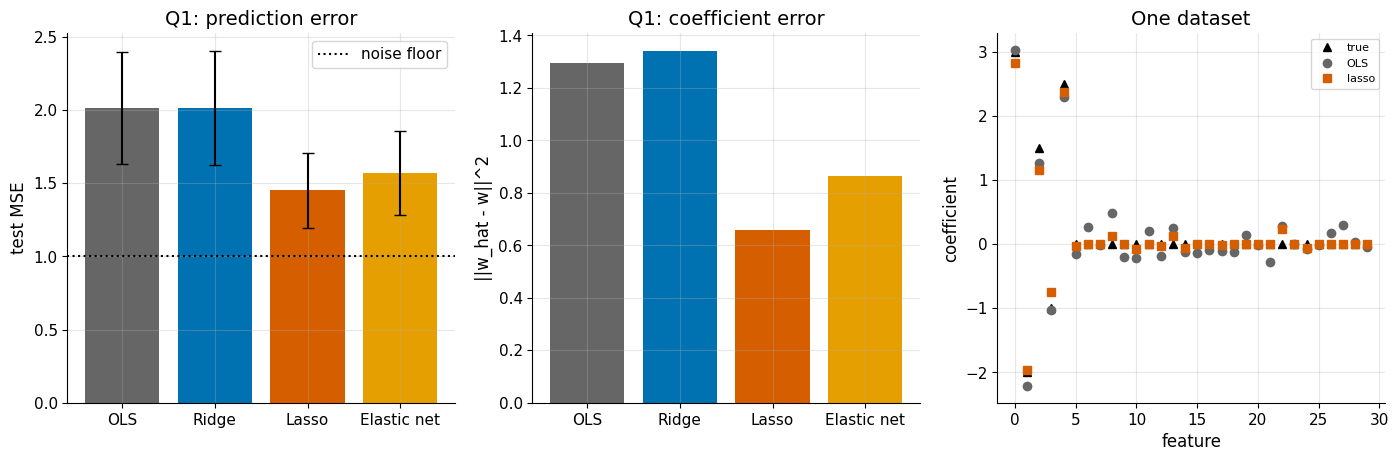

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); names = list(res); cols = [NEUTRAL, MAIN, HIGHLIGHT, SIM]; axes[0].bar(names, tb1["test MSE (incl. noise 1)"], yerr=tb1["SD of the test MSE"], color=cols, capsize=4); axes[0].axhline(1.0, color="black", linestyle=":", label="noise floor"); axes[0].legend(); axes[0].set_ylabel("test MSE"); axes[0].set_title("Q1: prediction error")
axes[1].bar(names, tb1["coefficient error ||w_hat - w||^2"], color=cols); axes[1].set_ylabel("||w_hat - w||^2"); axes[1].set_title("Q1: coefficient error")
Xa = make(np.random.default_rng(99), 60); ya = Xa @ wt + np.random.default_rng(100).normal(size=60); ya -= ya.mean(); wl = enet(Xa, ya, ll_grid[5]); wo = np.linalg.lstsq(Xa, ya, rcond=None)[0]; axes[2].plot(wt, "k^", label="true"); axes[2].plot(wo, "o", color=NEUTRAL, label="OLS"); axes[2].plot(wl, "s", color=HIGHLIGHT, label="lasso"); axes[2].legend(fontsize=8); axes[2].set_xlabel("feature"); axes[2].set_ylabel("coefficient"); axes[2].set_title("One dataset")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- Over 100 repetitions (60 observations, 30 features, 5 true) the test MSE including the noise variance 1 is **2.012 for OLS, 2.015 for ridge, 1.451 for the lasso and 1.570 for the elastic net**; the coefficient error $\|\hat w-w\|^2$ is **1.29, 1.34, 0.66 and 0.87**. OLS pays almost exactly the predicted excess ($\sigma^2p/(n-p-1)\approx1.03$, total 2.03). The sparse penalties remove about 55 % of the excess error; the lasso halves the coefficient error.
- **Ridge does not help here** (2.015 against 2.012 for OLS: its cross-validated $\lambda$ is small), because the 5 large true coefficients (up to 3) are exactly what a Gaussian prior with a common scale shrinks wrongly, while the 25 zeros are small anyway; ridge only wins when many coefficients are small *and* non-zero (Example 4).
- **The cross-validated lasso keeps too many features:** recall of the 5 true features is **1.00** but it selects on average **18.5 features** (precision **0.29**): the penalty chosen to minimise prediction error is smaller than the one that gives the correct support (the cross-validated $\lambda$ has a median of 3.17, 10th to 90th percentile 2.0 to 5.0). The KKT conditions of the solutions are met to $6\times10^{-9}$.
- **Decision.** Use the lasso (or elastic net) when you believe in a sparse truth and care about prediction; for support recovery use a larger $\lambda$ (the 1-standard-error rule) or a stability-selection check.

---
### Example 2: MAP against full Bayes, and choosing $\lambda$ by the evidence

**Scenario.** A regression with $n=40$, $p=15$, noise SD 1, true coefficients drawn from $N(0,\tau^2)$ with $\tau=0.7$. We compare (a) OLS, (b) ridge with the true $\lambda=\sigma^2/\tau^2=2.04$, (c) ridge with $\lambda$ chosen by the evidence, (d) ridge with $\lambda$ by 5-fold CV, and look at the width and coverage of the posterior intervals.

**Questions.** (1) Coefficient error and test MSE of each. (2) The $\lambda$ found by the evidence against the true one over 200 repetitions. (3) Coverage and width of the Bayesian 95 % intervals against OLS confidence intervals.

In [16]:
g = np.random.default_rng(21); R = 200; n, p, tau0, s0 = 40, 15, 0.7, 1.0; lam_true = s0 ** 2 / tau0 ** 2; out = {k: [] for k in ("OLS", "ridge, true lambda", "ridge, evidence", "ridge, 5-fold CV")}; lam_ev = []; cov_b = []; cov_o = []; wid_b = []; wid_o = []; grid = np.geomspace(0.1, 100, 25)
for r in range(R):
    w0 = tau0 * g.normal(size=p); Xa = g.normal(size=(n, p)); ya = Xa @ w0 + s0 * g.normal(size=n); Xt = g.normal(size=(4000, p)); yt = Xt @ w0
    evs = [log_evidence(Xa, ya, s0, s0 / np.sqrt(l)) for l in grid]; l_ev = grid[int(np.argmax(evs))]; lam_ev.append(l_ev); l_cv = grid[int(np.argmin([cv_err(lambda A, b_, l=l: ridge(A, b_, l), Xa, ya) for l in grid]))]
    for k, w_ in {"OLS": np.linalg.lstsq(Xa, ya, rcond=None)[0], "ridge, true lambda": ridge(Xa, ya, lam_true), "ridge, evidence": ridge(Xa, ya, l_ev), "ridge, 5-fold CV": ridge(Xa, ya, l_cv)}.items(): out[k].append((np.sum((w_ - w0) ** 2), np.mean((Xt @ w_ - yt) ** 2)))
    m_, S_ = posterior(Xa, ya, s0, tau0); cov_b.append(np.abs(w0 - m_) < 1.96 * np.sqrt(np.diag(S_))); wid_b.append(2 * 1.96 * np.sqrt(np.diag(S_)).mean()); wo = np.linalg.lstsq(Xa, ya, rcond=None)[0]; So = s0 ** 2 * np.linalg.inv(Xa.T @ Xa); cov_o.append(np.abs(w0 - wo) < 1.96 * np.sqrt(np.diag(So))); wid_o.append(2 * 1.96 * np.sqrt(np.diag(So)).mean())
tb2 = pd.DataFrame({k: {"coefficient error": np.mean([a for a, _ in v]), "test MSE (excess over noise)": np.mean([b_ for _, b_ in v])} for k, v in out.items()}).T; print("Q1:"); print(tb2.round(4).to_string())
print(f"Q2: lambda by the evidence: median {np.median(lam_ev):.2f} (true {lam_true:.2f}), 10th-90th percentile {np.quantile(lam_ev, 0.1):.2f} to {np.quantile(lam_ev, 0.9):.2f}")
print(f"Q3: coverage of the 95% interval: Bayesian ridge {np.mean(cov_b):.3f}, OLS {np.mean(cov_o):.3f}; mean interval width: Bayesian {np.mean(wid_b):.3f}, OLS {np.mean(wid_o):.3f}")

Q1:
                    coefficient error  test MSE (excess over noise)
OLS                            0.6283                        0.6294
ridge, true lambda             0.5515                        0.5526
ridge, evidence                0.5665                        0.5675
ridge, 5-fold CV               0.5699                        0.5712
Q2: lambda by the evidence: median 2.37 (true 2.04), 10th-90th percentile 1.33 to 4.22
Q3: coverage of the 95% interval: Bayesian ridge 0.950, OLS 0.949; mean interval width: Bayesian 0.750, OLS 0.799


### 12.5 Asserts

In [17]:
assert tb2.loc["ridge, true lambda", "coefficient error"] < tb2.loc["OLS", "coefficient error"] and tb2.loc["ridge, evidence", "coefficient error"] < tb2.loc["OLS", "coefficient error"] and abs(np.log(np.median(lam_ev) / lam_true)) < 0.7 and np.mean(wid_b) < np.mean(wid_o) and abs(np.mean(cov_b) - 0.95) < 0.02
print("all checks passed")

all checks passed


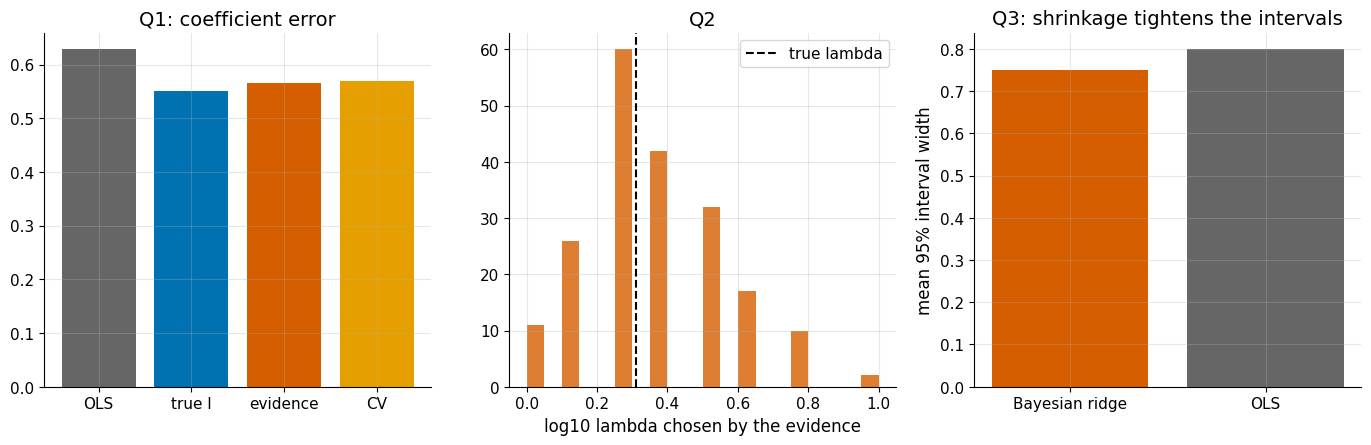

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); axes[0].bar(range(4), tb2["coefficient error"], color=[NEUTRAL, MAIN, HIGHLIGHT, SIM]); axes[0].set_xticks(range(4)); axes[0].set_xticklabels(["OLS", "true l", "evidence", "CV"]); axes[0].set_title("Q1: coefficient error")
axes[1].hist(np.log10(lam_ev), bins=20, color=HIGHLIGHT, alpha=0.8); axes[1].axvline(np.log10(lam_true), color="black", linestyle="--", label="true lambda"); axes[1].legend(); axes[1].set_xlabel("log10 lambda chosen by the evidence"); axes[1].set_title("Q2")
axes[2].bar([0, 1], [np.mean(wid_b), np.mean(wid_o)], color=[HIGHLIGHT, NEUTRAL]); axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["Bayesian ridge", "OLS"]); axes[2].set_ylabel("mean 95% interval width"); axes[2].set_title("Q3: shrinkage tightens the intervals")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- With a Gaussian truth ($\tau=0.7$, $n=40$, $p=15$) the coefficient error is **0.628 for OLS**, **0.552 for ridge with the true $\lambda=2.04$**, **0.567 with $\lambda$ chosen by the evidence** and **0.570 with 5-fold cross-validation**: a 10 % reduction, and the data-driven choices recover almost all of it (the test MSE excess falls from 0.629 to 0.553 to 0.568 and 0.571).
- The evidence recovers the prior strength: the median $\hat\lambda$ over 200 datasets is **2.37 against the true 2.04** (10th to 90th percentile 1.33 to 4.22), without any held-out data.
- The **Bayesian 95 % credible intervals cover the true coefficients 95.0 %** of the time (OLS confidence intervals 94.9 %), but are **6 % narrower** on average (0.750 against 0.799): when the prior is true, shrinkage gives the same coverage with a tighter interval.
- **Decision.** Treat $\lambda$ as a statement about the prior ($\sigma^2/\tau^2$) and estimate it from the data by the evidence or cross-validation; report posterior intervals, not just the MAP.

---
### Example 3: weight decay and early stopping are ridge

**Scenario.** For the regression of Example 1 (one dataset, $n=60$, $p=30$, noise SD 2.5) run plain gradient descent from $w=0$ with step $\eta$ chosen from the largest eigenvalue of $X^\top X$. (a) **Weight decay:** gradient descent on the ridge objective converges to the ridge solution. (b) **Early stopping:** unregularised gradient descent stopped after $k$ steps has the coefficient path of a ridge fit with $\lambda\approx1/(\eta k)$.

**Questions.** (1) Distance between the weight-decay solution and the closed-form ridge solution. (2) Test MSE of early-stopped gradient descent against ridge as $k$ grows, and the best stopping time. (3) How close is the early-stopping path to the ridge path with $\lambda=1/(\eta k)$?

In [19]:
g = np.random.default_rng(31); Xa = make(g, 60); ya = Xa @ wt + 2.5 * g.normal(size=60); ya -= ya.mean(); Xt = make(g, 5000); yt = Xt @ wt; S_ = Xa.T @ Xa; eta = 1.0 / np.linalg.eigvalsh(S_).max(); lamw = 20.0
w = np.zeros(30)
for _ in range(20000): w = (1 - eta * lamw) * w - eta * (S_ @ w - Xa.T @ ya)
print(f"Q1: weight decay (lambda = {lamw}) after 20,000 steps vs closed-form ridge: max |difference| = {np.abs(w - ridge(Xa, ya, lamw)).max():.2e}")
ks = [1, 3, 10, 30, 100, 300, 1000, 3000, 10000, 30000]; wk = np.zeros(30); path = {}; k_ = 0; errs = []
for k in range(1, 30001):
    wk = wk - eta * (S_ @ wk - Xa.T @ ya)
    if k in ks: path[k] = wk.copy(); errs.append((k, np.mean((Xt @ wk - yt) ** 2) + 6.25))
rid = [(1 / (eta * k), np.mean((Xt @ ridge(Xa, ya, 1 / (eta * k)) - yt) ** 2) + 6.25) for k in ks]; wols = np.linalg.lstsq(Xa, ya, rcond=None)[0]
tb3 = pd.DataFrame({"steps k": ks, "test MSE (early stopping)": [e for _, e in errs], "ridge lambda = 1/(eta k)": [a for a, _ in rid], "test MSE (ridge)": [b_ for _, b_ in rid], "distance between the two solutions": [np.linalg.norm(path[k] - ridge(Xa, ya, 1 / (eta * k))) / np.linalg.norm(ridge(Xa, ya, 1 / (eta * k))) for k in ks]}); print("Q2-Q3:"); print(tb3.round(4).to_string(index=False)); print(f"OLS test MSE {np.mean((Xt @ wols - yt) ** 2) + 6.25:.4f}; best early-stopping time on the grid: k = {tb3.loc[tb3['test MSE (early stopping)'].idxmin(), 'steps k']}")

Q1: weight decay (lambda = 20.0) after 20,000 steps vs closed-form ridge: max |difference| = 1.78e-15
Q2-Q3:
 steps k  test MSE (early stopping)  ridge lambda = 1/(eta k)  test MSE (ridge)  distance between the two solutions
       1                    15.7385                  349.5868           18.5948                              0.6208
       3                    13.0830                  116.5289           14.5613                              0.2867
      10                    10.5601                   34.9587           10.9950                              0.2765
      30                    10.6907                   11.6529            9.7465                              0.2516
     100                    12.1152                    3.4959           10.4297                              0.1690
     300                    12.5400                    1.1653           11.4871                              0.0846
    1000                    12.5488                    0.3496           12.1676

### 12.6 Asserts

In [20]:
assert np.abs(w - ridge(Xa, ya, lamw)).max() < 1e-6 and tb3["test MSE (early stopping)"].min() < np.mean((Xt @ wols - yt) ** 2) + 6.25 - 0.3 and abs(tb3["test MSE (early stopping)"].iloc[-1] - (np.mean((Xt @ wols - yt) ** 2) + 6.25)) < 0.05 and tb3["distance between the two solutions"].iloc[3:].max() < 0.35
print("all checks passed")

all checks passed


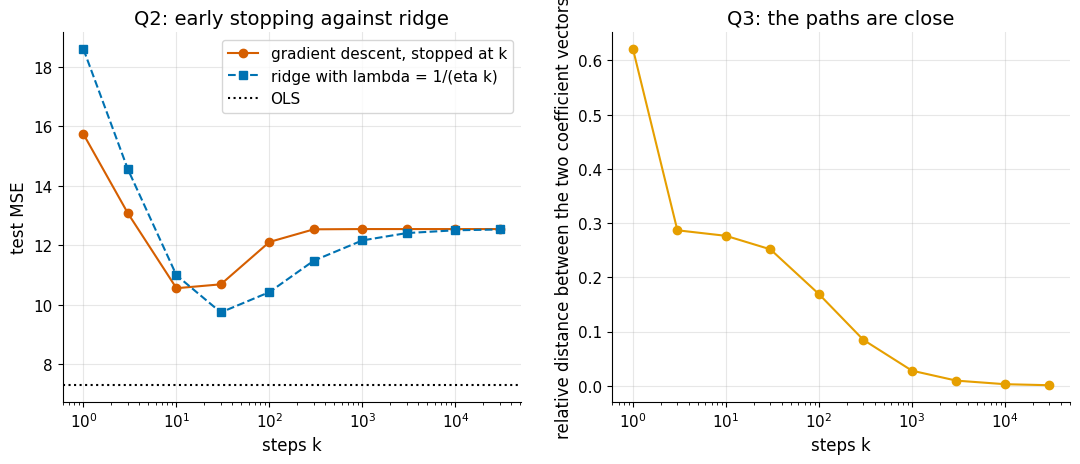

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].semilogx(ks, tb3["test MSE (early stopping)"], "o-", color=HIGHLIGHT, label="gradient descent, stopped at k"); axes[0].semilogx(ks, tb3["test MSE (ridge)"], "s--", color=MAIN, label="ridge with lambda = 1/(eta k)"); axes[0].axhline(np.mean((Xt @ wols - yt) ** 2) + 1, color="black", linestyle=":", label="OLS"); axes[0].legend(); axes[0].set_xlabel("steps k"); axes[0].set_ylabel("test MSE"); axes[0].set_title("Q2: early stopping against ridge")
axes[1].semilogx(ks, tb3["distance between the two solutions"], "o-", color=SIM); axes[1].set_xlabel("steps k"); axes[1].set_ylabel("relative distance between the two coefficient vectors"); axes[1].set_title("Q3: the paths are close")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- Gradient descent with weight decay ($\lambda=20$) converges to the closed-form ridge solution to **$2\times10^{-15}$**.
- With noise SD 2.5 (noise floor of the test MSE 6.25) the unregularised least-squares solution has a test MSE of **12.55**; gradient descent stopped early reaches **10.56 at 10 steps** and **12.12 at 100**, rising back to 12.55 as it converges to OLS; ridge with the matching $\lambda=1/(\eta k)$ reaches **9.75** (at $k=30$, $\lambda=11.7$). Both curves are U-shaped with a minimum at an intermediate amount of shrinkage.
- The early-stopped coefficients are close to the ridge solution with $\lambda=1/(\eta k)$: the relative distance between the two vectors is 0.28 at $k=10$, 0.17 at 100, 0.08 at 300 and below 0.03 from $k=1{,}000$. They are not identical, because the shrinkage factors differ ($1-(1-\eta s)^k$ against $s/(s+\lambda)$).
- **Decision.** Early stopping and weight decay are two ways of getting the same Gaussian prior; stop early (or decay) whenever the validation error starts to rise, and pick the amount on held-out data.

---
### Example 4: which prior is right? (sparse against dense truth)

**Scenario.** Two worlds with $n=60$, $p=30$, noise SD 1: **sparse** (5 coefficients of size about 2, the rest 0) and **dense** (all 30 coefficients drawn from $N(0,0.5^2)$). Ridge and lasso (cross-validated) are compared with OLS over 100 repetitions each.

**Questions.** (1) Test MSE of each method in each world. (2) How many features does the lasso select in each world? (3) Which method wins where, and by how much?

In [22]:
g = np.random.default_rng(41); worlds = {"sparse": lambda g: np.r_[2.0 * np.sign(g.normal(size=5)) * (1 + 0.3 * g.normal(size=5)), np.zeros(25)], "dense": lambda g: 0.5 * g.normal(size=30)}; R = 80; out4 = {}; nsel = {}
for wn, mk in worlds.items():
    acc = {"OLS": [], "Ridge": [], "Lasso": []}; ns_ = []
    for rep in range(R):
        w0 = mk(g); Xa = make(g, 60); ya = Xa @ w0 + g.normal(size=60); ya -= ya.mean(); Xt = make(g, 4000); yt = Xt @ w0
        wo = np.linalg.lstsq(Xa, ya, rcond=None)[0]; l_r = lr_grid[np.argmin([cv_err(lambda A, b_, l=l: ridge(A, b_, l), Xa, ya) for l in lr_grid])]; l_l = ll_grid[np.argmin([cv_err(lambda A, b_, l=l: enet(A, b_, l, iters=300, tol=1e-6), Xa, ya) for l in ll_grid])]; wl = enet(Xa, ya, l_l)
        for k, w_ in {"OLS": wo, "Ridge": ridge(Xa, ya, l_r), "Lasso": wl}.items(): acc[k].append(np.mean((Xt @ w_ - yt) ** 2) + 1)
        ns_.append(int((np.abs(wl) > 1e-8).sum()))
    out4[wn] = {k: np.mean(v) for k, v in acc.items()}; nsel[wn] = np.mean(ns_)
tb4 = pd.DataFrame(out4); print("Q1: test MSE (including the noise 1):"); print(tb4.round(3).to_string()); print(f"Q2: features selected by the lasso: sparse world {nsel['sparse']:.1f} (truth 5), dense world {nsel['dense']:.1f} (truth 30 small ones)")

Q1: test MSE (including the noise 1):
       sparse  dense
OLS     1.955  1.994
Ridge   1.947  1.793
Lasso   1.382  1.854
Q2: features selected by the lasso: sparse world 17.4 (truth 5), dense world 26.9 (truth 30 small ones)


### 12.7 Asserts

In [23]:
assert tb4.loc["Lasso", "sparse"] < tb4.loc["Ridge", "sparse"] and tb4.loc["Ridge", "dense"] < tb4.loc["Lasso", "dense"] + 0.05 and tb4.loc["Lasso", "sparse"] < tb4.loc["OLS", "sparse"] and tb4.loc["Ridge", "dense"] < tb4.loc["OLS", "dense"] and nsel["sparse"] < nsel["dense"]
print("all checks passed")

all checks passed


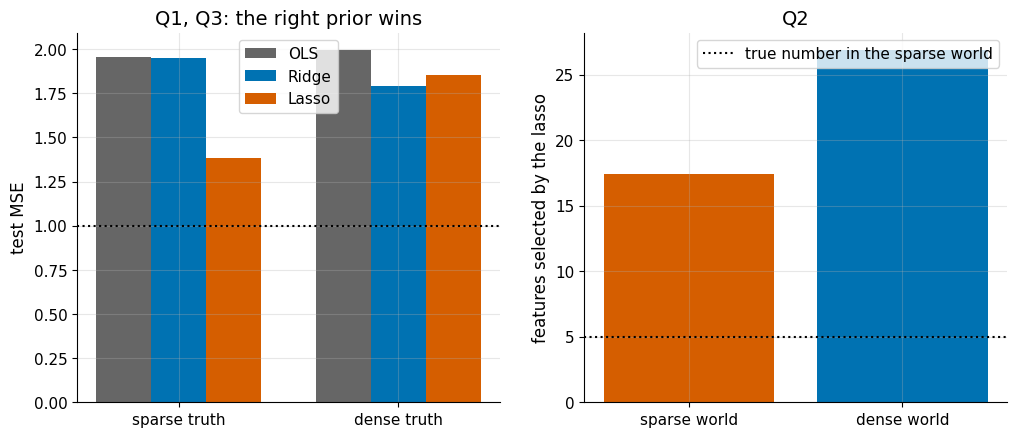

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8)); w = 0.25
for k, (m_, colr) in enumerate([("OLS", NEUTRAL), ("Ridge", MAIN), ("Lasso", HIGHLIGHT)]): axes[0].bar(np.arange(2) + (k - 1) * w, [tb4.loc[m_, "sparse"], tb4.loc[m_, "dense"]], w, color=colr, label=m_)
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["sparse truth", "dense truth"]); axes[0].axhline(1, color="black", linestyle=":"); axes[0].legend(); axes[0].set_ylabel("test MSE"); axes[0].set_title("Q1, Q3: the right prior wins")
axes[1].bar(["sparse world", "dense world"], [nsel["sparse"], nsel["dense"]], color=[HIGHLIGHT, MAIN]); axes[1].axhline(5, color="black", linestyle=":", label="true number in the sparse world"); axes[1].legend(); axes[1].set_ylabel("features selected by the lasso"); axes[1].set_title("Q2")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- **In a sparse world** (5 large coefficients) the test MSE is 1.955 (OLS), 1.947 (ridge) and **1.382 (lasso)**: the Laplace prior wins by 29 %. **In a dense world** (30 small coefficients) the order reverses: OLS 1.994, **ridge 1.793**, lasso 1.854: the Gaussian prior wins, by 10 % over OLS and 3 % over the lasso.
- The number of features the lasso keeps tells the same story: **17.4** in the sparse world (truth 5) against **26.9** in the dense world (truth: all 30, all small).
- **Decision.** The right penalty is the right belief about the coefficients: use the lasso when a few features should dominate and ridge (or an elastic net) when many features each contribute a little; when unsure, let cross-validation choose among them, as the elastic net does.

## 13. Where it is used

### Statistics
- **Penalised and Bayesian regression** (ridge, lasso, elastic net, the horseshoe prior), shrinkage and empirical Bayes (James-Stein), high-dimensional inference, **regularised GLMs** (09_02), model selection via the evidence.

### Data science
- **Feature selection and sparse models** for credit, churn and genomics, **stable coefficients under collinearity**, regularised forecasting, tuning by cross-validation, regularisation paths for model reports.

### ML and AI
- **Weight decay (AdamW)** in every large-scale training run, **$\ell_1$ and group sparsity** for pruning and compression, **LoRA/adapters** with decay, **early stopping, dropout and data augmentation** as implicit priors, **Bayesian neural networks** with Gaussian weight priors, and the MAP view of fine-tuning with a KL penalty to a base model (RLHF, 09_11).

## 14. Common pitfalls and misconceptions

- **Penalising unstandardised features:** the penalty depends on the units; standardise (and do not penalise the intercept).
- **Reading lasso selection as truth:** with correlated features the selected one is arbitrary; the selected set changes between samples (Example 1 recall below 1 and precision below 1).
- **Using the training error to choose $\lambda$:** it always favours $\lambda=0$; use cross-validation or the evidence.
- **Calling the MAP "the Bayesian answer":** it is a point estimate; the posterior also gives uncertainty (Example 2).
- **Forgetting the noise level:** the equivalent $\lambda$ is $\sigma^2/\tau^2$; a larger noise needs a larger penalty for the same prior.
- **Using ridge when the truth is sparse (or lasso when it is dense):** the best penalty depends on the structure (Example 4).
- **Shrunken coefficients are biased:** do not interpret them as unbiased effect sizes; for inference use post-selection methods or the posterior.
- **Early stopping and weight decay are not identical** for non-quadratic losses; they only agree approximately (Example 3).

## 15. Exercises

1. With $\sigma=2$ and a prior SD $\tau=0.5$ compute the ridge $\lambda$; with a Laplace prior of scale $b=0.5$ compute the lasso $\lambda$.
2. In an orthonormal design the OLS estimates are $(3.0,\,0.8,\,-1.4,\,0.2)$. Give the ridge ($\lambda=1$) and lasso ($\lambda=1$) estimates.
3. For $w=1$, $\sigma=1$ find the ridge $\lambda$ that minimises the MSE of $z/(1+\lambda)$, and the MSE reduction against OLS.
4. For the data of Example 3 compare the ridge posterior SD of the first coefficient with the OLS standard error.
5. Fit an elastic net with $\lambda_1=10$, $\lambda_2=5$ and a lasso with $\lambda=10$ to a dataset with two perfectly correlated features of equal effect; what happens to their coefficients?
6. (Harder) Show by simulation that the Bayesian lasso posterior mean (Laplace prior, sampled by random-walk Metropolis, 07_03) is not sparse while the lasso MAP is.

Solutions are at the end.

## 16. Summary table

| Method | Prior | Penalty | $\lambda$ | Effect |
|---|---|---|---|---|
| Ridge | Gaussian $N(0,\tau^2)$ | $\frac\lambda2\|w\|^2$ | $\sigma^2/\tau^2$ | smooth shrinkage, keeps all |
| Lasso | Laplace$(0,b)$ | $\lambda\|w\|_1$ | $\sigma^2/b$ | sparsity |
| Elastic net | mixture | both | two parameters | sparsity + grouping |
| Orthonormal ridge | | | | $z/(1+\lambda)$ |
| Orthonormal lasso | | | | $\mathrm{sign}(z)(|z|-\lambda)_+$ |
| Posterior (ridge) | | | | $N(\hat w,\sigma^2(X^\top X+\lambda I)^{-1})$ |
| Weight decay | | | | $w\leftarrow(1-\eta\lambda)w-\eta\nabla$ |
| tools | `np.linalg.solve`, coordinate descent | | | |

## Solutions

In [25]:
print(f"1: ridge lambda = sigma^2 / tau^2 = {2.0 ** 2 / 0.5 ** 2:.1f}; lasso lambda = sigma^2 / b = {2.0 ** 2 / 0.5:.1f}")
z4 = np.array([3.0, 0.8, -1.4, 0.2]); print("2: ridge (lambda = 1):", (z4 / 2).round(3), "| lasso (lambda = 1):", soft(z4, 1.0).round(3))
lg_ = np.linspace(0, 5, 5001); mse = (lg_ ** 2 * 1 + 1) / (1 + lg_) ** 2; print(f"3: best lambda = {lg_[np.argmin(mse)]:.3f} (theory sigma^2 / w^2 = 1), MSE {mse.min():.4f} vs 1.0 for OLS")
Xp1, yp1 = Xa, ya; so = np.sqrt(np.linalg.inv(Xp1.T @ Xp1)[0, 0]); sr = np.sqrt(np.linalg.inv(Xp1.T @ Xp1 + 20 * np.eye(30))[0, 0]); print(f"4: OLS standard error {so:.4f} vs ridge posterior SD (lambda = 20) {sr:.4f} (both for sigma = 1)")
g = np.random.default_rng(3); a = g.normal(size=100); Xc = np.column_stack([a, a]); yc = 2 * a + 0.1 * g.normal(size=100); Xc = Xc / Xc.std(axis=0); print("5: perfectly correlated features: lasso", enet(Xc, yc - yc.mean(), 10.0).round(3), "| elastic net", enet(Xc, yc - yc.mean(), 10.0, 5.0).round(3), "(the lasso puts the effect on one of them, the elastic net splits it)")
Xb = Xa[:, :6]; yb = ya; lamb = 5.0; b_ = 1.0 / lamb
def logpost(w): return -0.5 * np.sum((yb - Xb @ w) ** 2) - lamb * np.sum(np.abs(w))
w_cur = np.zeros(6); lp = logpost(w_cur); smp = []; gg = np.random.default_rng(4)
for it in range(40000):
    prop = w_cur + 0.05 * gg.normal(size=6); lpn = logpost(prop)
    if np.log(gg.random()) < lpn - lp: w_cur, lp = prop, lpn
    if it > 5000 and it % 10 == 0: smp.append(w_cur.copy())
smp = np.array(smp); print("6: Bayesian lasso posterior mean:", smp.mean(axis=0).round(3), "| lasso MAP:", enet(Xb, yb, lamb).round(3), "| share of samples with a coefficient within 0.001 of zero:", np.mean(np.abs(smp) < 0.001).round(4))
assert np.allclose(soft(z4, 1.0), [2.0, 0.0, -0.4, 0.0]) and abs(lg_[np.argmin(mse)] - 1.0) < 1e-3 and np.mean(np.abs(smp) < 0.001) < 0.05

1: ridge lambda = sigma^2 / tau^2 = 16.0; lasso lambda = sigma^2 / b = 8.0
2: ridge (lambda = 1): [ 1.5  0.4 -0.7  0.1] | lasso (lambda = 1): [ 2.   0.  -0.4  0. ]
3: best lambda = 1.000 (theory sigma^2 / w^2 = 1), MSE 0.5000 vs 1.0 for OLS
4: OLS standard error 0.2186 vs ridge posterior SD (lambda = 20) 0.1435 (both for sigma = 1)
5: perfectly correlated features: lasso [2.031 0.   ] | elastic net [0.991 0.991] (the lasso puts the effect on one of them, the elastic net splits it)


6: Bayesian lasso posterior mean: [ 1.257 -0.061  0.124  0.082 -0.489  0.922] | lasso MAP: [ 1.25  -0.     0.069  0.034 -0.483  0.936] | share of samples with a coefficient within 0.001 of zero: 0.0037


**1.** Ridge: $\lambda=\sigma^2/\tau^2=4/0.25=$ **16**; lasso: $\lambda=\sigma^2/b=4/0.5=$ **8**.

**2.** Ridge ($\lambda=1$) halves every estimate: $(1.5,\,0.4,\,-0.7,\,0.1)$; the lasso ($\lambda=1$) gives $(2.0,\,0,\,-0.4,\,0)$: the two small estimates are set exactly to zero, the large ones shrink by 1.

**3.** The MSE $(\lambda^2w^2+\sigma^2)/(1+\lambda)^2$ is minimised at $\lambda=\sigma^2/w^2=$ **1**, where it equals **0.5**: shrinkage halves the error of OLS (1.0).

**4.** The OLS standard error of the first coefficient is **0.219** and the posterior SD of ridge ($\lambda=20$) is **0.144**: the prior removes about a third of the uncertainty.

**5.** With two identical features the lasso puts the whole effect on one of them, **(2.03, 0)**, while the elastic net splits it equally, **(0.99, 0.99)**: the grouping effect of the ridge part.

**6.** The Bayesian lasso posterior mean is $(1.257,-0.061,0.124,0.082,-0.489,0.922)$ and the lasso MAP is $(1.25,0,0.069,0.034,-0.483,0.936)$; only **0.4 %** of the posterior samples have a coefficient within 0.001 of zero: the posterior mean is not sparse even though the mode is.